In [1]:
%pip install mysql-connector-python pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import mysql.connector
import pandas as pd 

import matplotlib.pyplot as plt


print("MySQL Connector is ready!")

MySQL Connector is ready!


In [3]:
import os
connection = mysql.connector.connect(
    host = os.getenv('MYSQL_HOST', 'localhost'),
    user = os.getenv('MYSQL_USER', 'root'),
    password = os.getenv('MYSQL_PASSWORD', 'your_password_here'),
    database = os.getenv('MYSQL_DATABASE', 'household_chores_db')
)
if connection.is_connected():
    print("Successfully connected to the database!")

Successfully connected to the database!


In [4]:
query = "Select * from tasks"
cursor = connection.cursor()
cursor.execute(query)

results = cursor.fetchall()
print(results)

[(1, 'sweep and mop', 'cleaning', 7, 30, 1), (2, 'clean bathroon', 'cleaning', 2, 25, 1), (3, 'wash dishes', 'cleaning', 7, 10, 1), (4, 'laundry', 'cleaning', 2, 80, 1), (5, 'buy water', 'water', 2, 20, 1), (6, 'cook meals', 'cooking', 2, 30, 1), (7, 'grocery shopping', 'shopping', 1, 20, 1), (8, 'organize room', 'cleaning', 3, 25, 1)]


In [5]:
connection.reconnect(attempts=2, delay=2)
print(connection.is_connected())

True


In [6]:
cursor.execute("SELECT * FROM tasks")
rows = cursor.fetchall()
for row in rows:
    if row in rows:
        print(rows)


[(1, 'sweep and mop', 'cleaning', 7, 30, 1), (2, 'clean bathroon', 'cleaning', 2, 25, 1), (3, 'wash dishes', 'cleaning', 7, 10, 1), (4, 'laundry', 'cleaning', 2, 80, 1), (5, 'buy water', 'water', 2, 20, 1), (6, 'cook meals', 'cooking', 2, 30, 1), (7, 'grocery shopping', 'shopping', 1, 20, 1), (8, 'organize room', 'cleaning', 3, 25, 1)]
[(1, 'sweep and mop', 'cleaning', 7, 30, 1), (2, 'clean bathroon', 'cleaning', 2, 25, 1), (3, 'wash dishes', 'cleaning', 7, 10, 1), (4, 'laundry', 'cleaning', 2, 80, 1), (5, 'buy water', 'water', 2, 20, 1), (6, 'cook meals', 'cooking', 2, 30, 1), (7, 'grocery shopping', 'shopping', 1, 20, 1), (8, 'organize room', 'cleaning', 3, 25, 1)]
[(1, 'sweep and mop', 'cleaning', 7, 30, 1), (2, 'clean bathroon', 'cleaning', 2, 25, 1), (3, 'wash dishes', 'cleaning', 7, 10, 1), (4, 'laundry', 'cleaning', 2, 80, 1), (5, 'buy water', 'water', 2, 20, 1), (6, 'cook meals', 'cooking', 2, 30, 1), (7, 'grocery shopping', 'shopping', 1, 20, 1), (8, 'organize room', 'cleaning

In [7]:
cursor.execute("SELECT * FROM tasks")
rows = cursor.fetchall()
print(rows)

[(1, 'sweep and mop', 'cleaning', 7, 30, 1), (2, 'clean bathroon', 'cleaning', 2, 25, 1), (3, 'wash dishes', 'cleaning', 7, 10, 1), (4, 'laundry', 'cleaning', 2, 80, 1), (5, 'buy water', 'water', 2, 20, 1), (6, 'cook meals', 'cooking', 2, 30, 1), (7, 'grocery shopping', 'shopping', 1, 20, 1), (8, 'organize room', 'cleaning', 3, 25, 1)]


In [8]:
cursor.execute("SELECT * FROM tasks")
rows = cursor.fetchall()

columns = [description[0] for description in cursor.description]
tasks_df = pd.DataFrame(rows, columns=columns)
print(tasks_df)

   task_id         task_name  category  frequency_per_week  estimated_minutes  \
0        1     sweep and mop  cleaning                   7                 30   
1        2    clean bathroon  cleaning                   2                 25   
2        3       wash dishes  cleaning                   7                 10   
3        4           laundry  cleaning                   2                 80   
4        5         buy water     water                   2                 20   
5        6        cook meals   cooking                   2                 30   
6        7  grocery shopping  shopping                   1                 20   
7        8     organize room  cleaning                   3                 25   

   can_batch  
0          1  
1          1  
2          1  
3          1  
4          1  
5          1  
6          1  
7          1  


In [9]:
tasks_df

,task_id,task_name,category,frequency_per_week,estimated_minutes,can_batch
0,1,sweep and mop,cleaning,7,30,1
1,2,clean bathroon,cleaning,2,25,1
2,3,wash dishes,cleaning,7,10,1
3,4,laundry,cleaning,2,80,1
4,5,buy water,water,2,20,1
5,6,cook meals,cooking,2,30,1
6,7,grocery shopping,shopping,1,20,1
7,8,organize room,cleaning,3,25,1


In [10]:
print("HOUSEHOLD CHORE DATASET ")
tasks_df.head()





HOUSEHOLD CHORE DATASET 


,task_id,task_name,category,frequency_per_week,estimated_minutes,can_batch
0,1,sweep and mop,cleaning,7,30,1
1,2,clean bathroon,cleaning,2,25,1
2,3,wash dishes,cleaning,7,10,1
3,4,laundry,cleaning,2,80,1
4,5,buy water,water,2,20,1


In [11]:
print("\n Dataset Shape:")
tasks_df.shape



 Dataset Shape:


(8, 6)

In [12]:
print("\nColumns Names: ")
tasks_df.columns.tolist()



Columns Names: 


['task_id',
 'task_name',
 'category',
 'frequency_per_week',
 'estimated_minutes',
 'can_batch']

In [13]:
print("\nMissing values: ")
tasks_df.isnull().sum()



Missing values: 


task_id               0
task_name             0
category              0
frequency_per_week    0
estimated_minutes     0
can_batch             0
dtype: int64

In [14]:
print("WEEKLY CHORE DURATION ANALYSIS ")
tasks_df["weekly_duration"] =(tasks_df["estimated_minutes"] * tasks_df["frequency_per_week"])

print(tasks_df[[
    'task_name',
  'frequency_per_week',
  'estimated_minutes',
    "weekly_duration"
]])

WEEKLY CHORE DURATION ANALYSIS 
          task_name  frequency_per_week  estimated_minutes  weekly_duration
0     sweep and mop                   7                 30              210
1    clean bathroon                   2                 25               50
2       wash dishes                   7                 10               70
3           laundry                   2                 80              160
4         buy water                   2                 20               40
5        cook meals                   2                 30               60
6  grocery shopping                   1                 20               20
7     organize room                   3                 25               75


In [15]:
print("CHORES RANKED BY WEEKLY DURATION")

ranked_tasks = tasks_df.sort_values(
    by = "weekly_duration", ascending = False)

print(ranked_tasks[[
    'task_name','frequency_per_week', "weekly_duration"
]])

CHORES RANKED BY WEEKLY DURATION
          task_name  frequency_per_week  weekly_duration
0     sweep and mop                   7              210
3           laundry                   2              160
7     organize room                   3               75
2       wash dishes                   7               70
5        cook meals                   2               60
1    clean bathroon                   2               50
4         buy water                   2               40
6  grocery shopping                   1               20


In [16]:
print("Column names:")
print(tasks_df.columns.tolist())

print("\nFirst 10 chore records:")
display(tasks_df.head(10))

Column names:
['task_id', 'task_name', 'category', 'frequency_per_week', 'estimated_minutes', 'can_batch', 'weekly_duration']

First 10 chore records:


,task_id,task_name,category,frequency_per_week,estimated_minutes,can_batch,weekly_duration
0,1,sweep and mop,cleaning,7,30,1,210
1,2,clean bathroon,cleaning,2,25,1,50
2,3,wash dishes,cleaning,7,10,1,70
3,4,laundry,cleaning,2,80,1,160
4,5,buy water,water,2,20,1,40
5,6,cook meals,cooking,2,30,1,60
6,7,grocery shopping,shopping,1,20,1,20
7,8,organize room,cleaning,3,25,1,75


In [17]:
# 1. Identify high-frequency chores
high_frequency = tasks_df.sort_values(
    by="frequency_per_week",
    ascending=False
)

print("HIGH-FREQUENCY CHORES")
display(
    high_frequency[
        ["task_name", "frequency_per_week"]
    ]
)



HIGH-FREQUENCY CHORES


,task_name,frequency_per_week
0,sweep and mop,7
2,wash dishes,7
7,organize room,3
1,clean bathroon,2
3,laundry,2
4,buy water,2
5,cook meals,2
6,grocery shopping,1


In [18]:
# 2. Identify the most time-consuming chores
time_consuming = tasks_df.sort_values(
    by="weekly_duration",
    ascending=False
)

print("MOST TIME-CONSUMING CHORES")
display(
    time_consuming[
        ["task_name", "weekly_duration"]
    ]
)

MOST TIME-CONSUMING CHORES


,task_name,weekly_duration
0,sweep and mop,210
3,laundry,160
7,organize room,75
2,wash dishes,70
5,cook meals,60
1,clean bathroon,50
4,buy water,40
6,grocery shopping,20


In [19]:
print("CHORE BATCHING RECOMMEDATION")

bacthable_tasks = tasks_df.groupby("category").agg(
    number_of_chores = ("task_name","count"),
    total_weekly_duration = ("weekly_duration", "sum")).reset_index()



bacthable_tasks = bacthable_tasks.sort_values(
    by = "number_of_chores" ,
    ascending = False
)

bacthable_tasks
                                                   

CHORE BATCHING RECOMMEDATION


,category,number_of_chores,total_weekly_duration
0,cleaning,5,565
1,cooking,1,60
2,shopping,1,20
3,water,1,40


In [20]:
print("CHORE BATCHING RECOMMENDATION")

batchable_tasks = tasks_df[tasks_df["can_batch"] == 1].copy()

batchable_tasks = batchable_tasks.groupby("category").agg(
    number_of_chores=("task_name", "count"),
    total_weekly_duration=("weekly_duration", "sum"),
    chores=("task_name", list)
).reset_index()

batchable_tasks = batchable_tasks.sort_values(
    by="number_of_chores",
    ascending=False
)

display(batchable_tasks)

CHORE BATCHING RECOMMENDATION


,category,number_of_chores,total_weekly_duration,chores
0,cleaning,5,565,"[sweep and mop, clean bathroon, wash dishes, l..."
1,cooking,1,60,[cook meals]
2,shopping,1,20,[grocery shopping]
3,water,1,40,[buy water]


In [21]:
print("SUGGESTED WEEKLY CHORE SCHEDULE")

days = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"

]

schedule = tasks_df .copy()

schedule["suggested_day"] = [
    days[i % len(days)] 
    for i in range(len(schedule)) ]

schedule[[
        'task_name',
        "weekly_duration",
        "suggested_day"
    ]]
    

SUGGESTED WEEKLY CHORE SCHEDULE


,task_name,weekly_duration,suggested_day
0,sweep and mop,210,Monday
1,clean bathroon,50,Tuesday
2,wash dishes,70,Wednesday
3,laundry,160,Thursday
4,buy water,40,Friday
5,cook meals,60,Saturday
6,grocery shopping,20,Sunday
7,organize room,75,Monday


In [22]:

# Days of the week
days = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

# Track the scheduled minutes for each day
daily_minutes = {day: 0 for day in days}

# Store the scheduled chores
schedule = []

# Schedule chores with the longest weekly workload first
sorted_tasks = tasks_df.sort_values(
    by="weekly_duration",
    ascending=False
)

for _, task in sorted_tasks.iterrows():

    frequency = int(task["frequency_per_week"])

    if frequency < 0 or frequency > 7:
        raise ValueError(
            f"Invalid weekly frequency for {task['task_name']}"
        )

    # Estimated time for one occurrence
    duration = task["estimated_minutes"]

    for _ in range(frequency):

        # Select the day with the lowest scheduled workload
        day = min(days, key=lambda d: daily_minutes[d])

        # Add the chore to that day
        schedule.append({
            "day": day,
            "task_name": task["task_name"],
            "category": task["category"],
            "duration_minutes": duration
        })

        # Update the day's workload
        daily_minutes[day] += duration

# Convert the schedule to a DataFrame
weekly_schedule = pd.DataFrame(schedule)

# Display the suggested weekly schedule
display(
    weekly_schedule.sort_values(
        by=["day", "category", "task_name"]
    )
)

,day,task_name,category,duration_minutes
11,Friday,organize room,cleaning,25
4,Friday,sweep and mop,cleaning,30
20,Friday,cook meals,cooking,30
7,Monday,laundry,cleaning,80
0,Monday,sweep and mop,cleaning,30
21,Saturday,clean bathroon,cleaning,25
5,Saturday,sweep and mop,cleaning,30
12,Saturday,wash dishes,cleaning,10
14,Saturday,wash dishes,cleaning,10
16,Saturday,wash dishes,cleaning,10


In [23]:
print("SUGGESTED WEEKLY CHORE SCHEDULE")

days = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

schedule_rows = []

for _, task in tasks_df.iterrows():
    frequency = int(task["frequency_per_week"])

    for occurrence in range(frequency):
        day_index = (
            occurrence * len(days) // frequency
        )

        schedule_rows.append({
            "task_name": task["task_name"],
            "category": task["category"],
            "suggested_day": days[day_index],
            "duration_minutes": task["estimated_minutes"]
        })

weekly_schedule = pd.DataFrame(schedule_rows)

display(
    weekly_schedule.sort_values(
        by=["suggested_day", "category", "task_name"]
    )
)

SUGGESTED WEEKLY CHORE SCHEDULE


,task_name,category,suggested_day,duration_minutes
25,organize room,cleaning,Friday,25
4,sweep and mop,cleaning,Friday,30
13,wash dishes,cleaning,Friday,10
7,clean bathroon,cleaning,Monday,25
16,laundry,cleaning,Monday,80
23,organize room,cleaning,Monday,25
0,sweep and mop,cleaning,Monday,30
9,wash dishes,cleaning,Monday,10
20,cook meals,cooking,Monday,30
22,grocery shopping,shopping,Monday,20


In [24]:

print("POTENTIAL WEEKLY TIME SAVINGS")

# Assumed time savings from batching
batching_savings_rate = 0.15

# Calculate total current weekly chore duration
current_weekly_duration = tasks_df["weekly_duration"].sum()

# Select chores that can be batched
batchable_tasks = tasks_df[tasks_df["can_batch"] == 1]

# Calculate weekly duration of batchable chores
batchable_weekly_duration = batchable_tasks["weekly_duration"].sum()

# Estimate time saved through batching
estimated_time_saved = (
    batchable_weekly_duration * batching_savings_rate
)

# Calculate estimated weekly duration after batching
optimized_weekly_duration = (
    current_weekly_duration - estimated_time_saved
)

# Display the results
savings_summary = pd.DataFrame({
    "Metric": [
        "Current weekly chore duration",
        "Weekly duration of batchable chores",
        "Estimated weekly time saved",
        "Estimated weekly duration after batching"
    ],
    "Minutes": [
        current_weekly_duration,
        batchable_weekly_duration,
        round(estimated_time_saved, 2),
        round(optimized_weekly_duration, 2)
    ]
})

display(savings_summary)

print(
    f"Estimated time saved per week: "
    f"{estimated_time_saved:.2f} minutes"
)

print(
    f"Estimated time saved per week: "
    f"{estimated_time_saved / 60:.2f} hours"
)


POTENTIAL WEEKLY TIME SAVINGS


,Metric,Minutes
0,Current weekly chore duration,685.00
1,Weekly duration of batchable chores,685.00
2,Estimated weekly time saved,102.75
3,Estimated weekly duration after batching,582.25


Estimated time saved per week: 102.75 minutes
Estimated time saved per week: 1.71 hours


In [25]:

print("SMART HOUSEHOLD CHORE OPTIMIZER")
print("=" * 40)

# 1. Count the total number of chores
total_chores = len(tasks_df)

# 2. Count chores that can be batched
batchable_count = (tasks_df["can_batch"] == 1).sum()

# 3. Count chores that cannot be batched
non_batchable_count = (tasks_df["can_batch"] == 0).sum()

# 4. Calculate total weekly duration
current_weekly_duration = tasks_df["weekly_duration"].sum()

# 5. Calculate estimated time saved
batching_savings_rate = 0.15

batchable_weekly_duration = tasks_df.loc[
    tasks_df["can_batch"] == 1,
    "weekly_duration"
].sum()

estimated_time_saved = (
    batchable_weekly_duration * batching_savings_rate
)

optimized_weekly_duration = (
    current_weekly_duration - estimated_time_saved
)

# 6. Create the final summary
optimization_summary = pd.DataFrame({
    "Metric": [
        "Total number of chores",
        "Chores that can be batched",
        "Chores that cannot be batched",
        "Current weekly workload (minutes)",
        "Estimated weekly time saved (minutes)",
        "Estimated workload after batching (minutes)",
        "Estimated time saved (hours)"
    ],
    "Value": [
        total_chores,
        batchable_count,
        non_batchable_count,
        current_weekly_duration,
        round(estimated_time_saved, 2),
        round(optimized_weekly_duration, 2),
        round(estimated_time_saved / 60, 2)
    ]
})

# display(optimization_summary)
optimization_summary


SMART HOUSEHOLD CHORE OPTIMIZER


,Metric,Value
0,Total number of chores,8.00
1,Chores that can be batched,8.00
2,Chores that cannot be batched,0.00
3,Current weekly workload (minutes),685.00
4,Estimated weekly time saved (minutes),102.75
5,Estimated workload after batching (minutes),582.25
6,Estimated time saved (hours),1.71


In [26]:

print("STEP 31: DATA VALIDATION")
print("=" * 40)

# 1. Check for missing values
print("\n1. Missing values per column:")
display(tasks_df.isnull().sum())

# 2. Check for duplicate task IDs
print("\n2. Duplicate task IDs:")
print(tasks_df["task_id"].duplicated().sum())


# 3. Check for invalid weekly frequencies
print("\n3. Chores with invalid frequencies:")
invalid_frequency = tasks_df[
    (tasks_df["frequency_per_week"] < 0) |
    (tasks_df["frequency_per_week"] > 7)
]
display(invalid_frequency)



# 4. Check for non-positive estimated durations
print("\n4. Chores with non-positive durations:")
invalid_duration = tasks_df[
    tasks_df["estimated_minutes"] <= 0
]
display(invalid_duration)

# 5. Verify weekly duration calculations
print("\n5. Weekly duration inconsistencies:")
duration_check = tasks_df[
    tasks_df["weekly_duration"] !=
    tasks_df["frequency_per_week"] *
    tasks_df["estimated_minutes"]
]
display(duration_check)

# 6. Check whether can_batch contains valid values
print("\n6. Invalid can_batch values:")
invalid_batch = tasks_df[
    ~tasks_df["can_batch"].isin([0, 1])
]
display(invalid_batch)

print("\nDATA VALIDATION COMPLETE")



STEP 31: DATA VALIDATION

1. Missing values per column:


task_id               0
task_name             0
category              0
frequency_per_week    0
estimated_minutes     0
can_batch             0
weekly_duration       0
dtype: int64


2. Duplicate task IDs:
0

3. Chores with invalid frequencies:


,task_id,task_name,category,frequency_per_week,estimated_minutes,can_batch,weekly_duration



4. Chores with non-positive durations:


...


5. Weekly duration inconsistencies:


,task_id,task_name,category,frequency_per_week,estimated_minutes,can_batch,weekly_duration



6. Invalid can_batch values:


,task_id,task_name,category,frequency_per_week,estimated_minutes,can_batch,weekly_duration



DATA VALIDATION COMPLETE


In [27]:

print("STEP 32: SCENARIO TESTING")
print("=" * 40)

# Create a temporary copy for testing
test_df = tasks_df.copy()

# Scenario 1: Increase the frequency of the first chore
test_df.loc[test_df.index[0], "frequency_per_week"] += 1

# Scenario 2: Recalculate weekly duration
test_df["weekly_duration"] = (
    test_df["frequency_per_week"] *
    test_df["estimated_minutes"]
)

print("\n1. Scenario: Increased chore frequency")
display(
    test_df[[
        "task_name",
        "frequency_per_week",
        "estimated_minutes",
        "weekly_duration"
    ]].head()
)

# Scenario 3: Compare the original and changed weekly workload
original_total = tasks_df["weekly_duration"].sum()
test_total = test_df["weekly_duration"].sum()

print("\n2. Original weekly workload:", original_total, "minutes")
print("3. Test weekly workload:", test_total, "minutes")
print("4. Difference:", test_total - original_total, "minutes")

# Scenario 4: Test batchability counts
test_df.loc[test_df.index[0], "can_batch"] = 0

original_batchable_count = (tasks_df["can_batch"] == 1).sum()
test_batchable_count = (test_df["can_batch"] == 1).sum()

print("\n5. Original batchable chores:", original_batchable_count)
print("6. Test batchable chores:", test_batchable_count)

# Confirm the original dataset was not changed
print(
    "\n7. Original dataset unchanged:",
    tasks_df["weekly_duration"].sum() == original_total
)


STEP 32: SCENARIO TESTING

1. Scenario: Increased chore frequency


,task_name,frequency_per_week,estimated_minutes,weekly_duration
0,sweep and mop,8,30,240
1,clean bathroon,2,25,50
2,wash dishes,7,10,70
3,laundry,2,80,160
4,buy water,2,20,40



2. Original weekly workload: 685 minutes
3. Test weekly workload: 715 minutes
4. Difference: 30 minutes

5. Original batchable chores: 8
6. Test batchable chores: 7

7. Original dataset unchanged: True


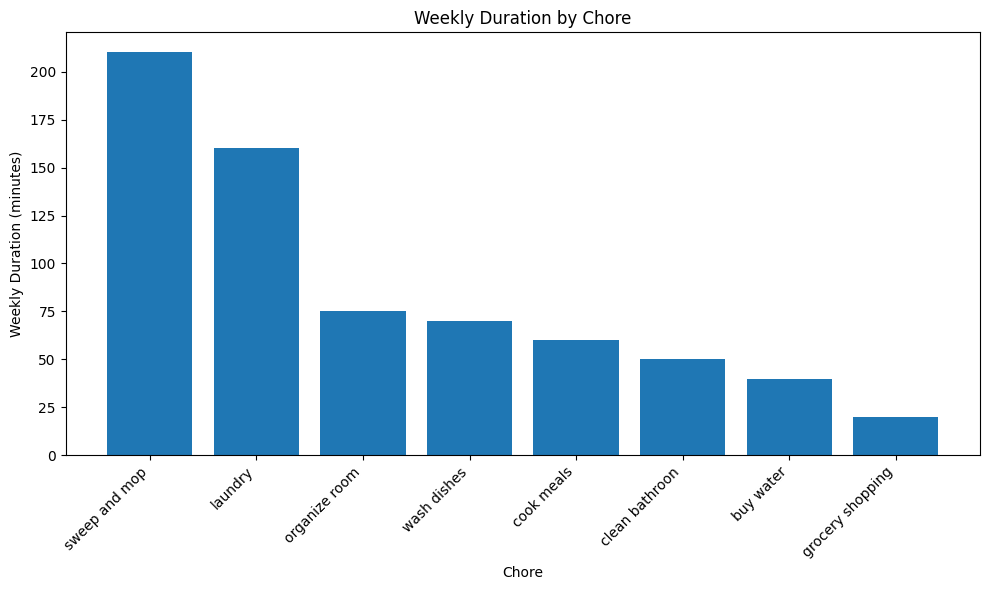

In [28]:

# Weekly duration by chore
duration_by_chore = tasks_df.sort_values(
    by="weekly_duration",
    ascending=False
)

plt.figure(figsize=(10, 6))

plt.bar(
    duration_by_chore["task_name"],
    duration_by_chore["weekly_duration"]
)

plt.title("Weekly Duration by Chore")
plt.xlabel("Chore")
plt.ylabel("Weekly Duration (minutes)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


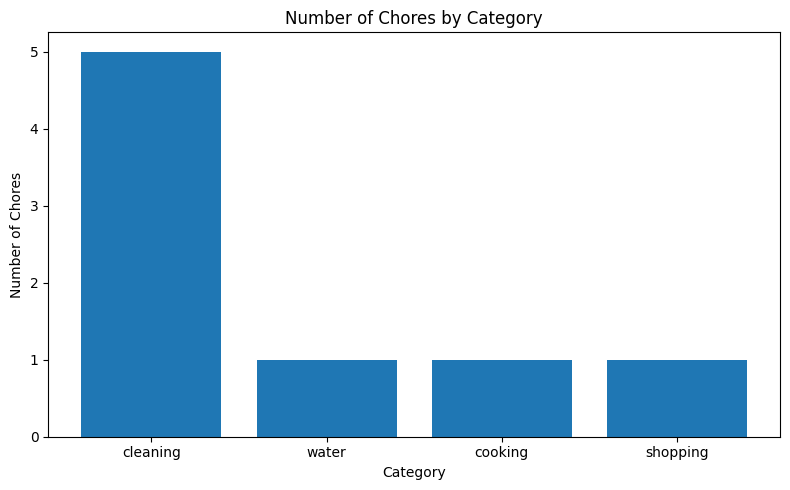

In [29]:

# Number of chores by category
chores_by_category = tasks_df["category"].value_counts()

plt.figure(figsize=(8, 5))

plt.bar(
    chores_by_category.index,
    chores_by_category.values
)

plt.title("Number of Chores by Category")
plt.xlabel("Category")
plt.ylabel("Number of Chores")
plt.tight_layout()
plt.show()


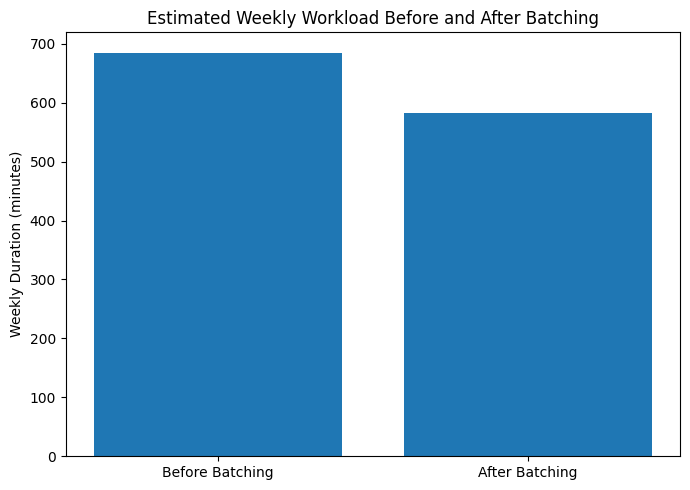

In [30]:
# weekly workload before and after batching


# Calculate comparison values
current_weekly_duration = tasks_df["weekly_duration"].sum()

batchable_weekly_duration = tasks_df.loc[
    tasks_df["can_batch"] == 1,
    "weekly_duration"
].sum()

estimated_time_saved = batchable_weekly_duration * 0.15

optimized_weekly_duration = (
    current_weekly_duration - estimated_time_saved
)

# Plot comparison
labels = ["Before Batching", "After Batching"]
durations = [
    current_weekly_duration,
    optimized_weekly_duration
]

plt.figure(figsize=(7, 5))

plt.bar(labels, durations)

plt.title("Estimated Weekly Workload Before and After Batching")
plt.ylabel("Weekly Duration (minutes)")
plt.tight_layout()
plt.show()


In [31]:

print("STEP 34: EXPORT OPTIMIZATION RESULTS")

# Name of the Excel workbook
output_file = "Smart_Household_Chore_Optimizer.xlsx"

# Create a summary of weekly chore duration by category
category_summary = tasks_df.groupby("category").agg(
    number_of_chores=("task_name", "count"),
    total_weekly_duration=("weekly_duration", "sum")
).reset_index()

# Export the results to separate Excel sheets
with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    tasks_df.to_excel(
        writer, sheet_name="Chore Data", index=False
    )

    weekly_schedule.to_excel(
        writer, sheet_name="Weekly Schedule", index=False
    )

    batchable_tasks.to_excel(
        writer, sheet_name="Batching Summary", index=False
    )

    optimization_summary.to_excel(
        writer, sheet_name="Optimization Summary", index=False
    )

    category_summary.to_excel(
        writer, sheet_name="Category Summary", index=False
    )

print(f"Excel workbook created: {output_file}")


STEP 34: EXPORT OPTIMIZATION RESULTS
Excel workbook created: Smart_Household_Chore_Optimizer.xlsx


In [32]:

import os

if os.path.exists(output_file):
    print("Export successful!")
    print("File size:", round(os.path.getsize(output_file) / 1024, 2), "KB")
    print("Saved location:", os.path.abspath(output_file))
else:
    print("Export failed. Check the error message.")


Export successful!
File size: 8.37 KB
Saved location: C:\Users\DELL\Desktop\Smart_Household_hore_Optimizer\Smart_Household_Chore_Optimizer.xlsx


In [33]:

print("SMART HOUSEHOLD CHORE OPTIMIZER")
print("=" * 45)

# Calculate project metrics
total_chores = len(tasks_df)
total_weekly_minutes = tasks_df["weekly_duration"].sum()

batchable_count = (
    tasks_df["can_batch"] == 1
).sum()

batchable_minutes = tasks_df.loc[
    tasks_df["can_batch"] == 1,
    "weekly_duration"
].sum()

# Illustrative 15% batching assumption
estimated_savings = batchable_minutes * 0.15
estimated_remaining_minutes = (
    total_weekly_minutes - estimated_savings
)

category_summary = tasks_df.groupby("category").agg(
    chore_count=("task_name", "count"),
    weekly_minutes=("weekly_duration", "sum")
).reset_index()

longest_chore = tasks_df.loc[
    tasks_df["weekly_duration"].idxmax()
]

print("\nPROJECT OVERVIEW")
print("A Python and MySQL project that analyzes")
print("household chores and suggests ways to organize")
print("weekly tasks and identify batching opportunities.")

print("\nKEY METRICS")
print(f"Total chores: {total_chores}")
print(f"Current weekly workload: {total_weekly_minutes} minutes")
print(f"Batchable chores: {batchable_count}")
print(f"Estimated time saved: {estimated_savings:.2f} minutes/week")
print(
    "Estimated workload after batching: "
    f"{estimated_remaining_minutes:.2f} minutes/week"
)

print("\nCHORE WITH THE HIGHEST WEEKLY DURATION")
print("Chore:", longest_chore["task_name"])
print("Weekly duration:", longest_chore["weekly_duration"], "minutes")

print("\nWORKLOAD BY CATEGORY")
display(category_summary)

print("\nTOOLS AND SKILLS USED")
print("- MySQL and SQL queries")
print("- Python and pandas")
print("- Jupyter Notebook")
print("- Matplotlnib visualizations")
print("- Excel report export")
print("- Data validation and scenario testing")

print("\nLIMITATION")
print(
    "Time savings are estimated using an assumed 15% batching rate. "
    "Actual savings may differ."
)

print("\nPROJECT REPORT COMPLETE")


SMART HOUSEHOLD CHORE OPTIMIZER

PROJECT OVERVIEW
A Python and MySQL project that analyzes
household chores and suggests ways to organize
weekly tasks and identify batching opportunities.

KEY METRICS
Total chores: 8
Current weekly workload: 685 minutes
Batchable chores: 8
Estimated time saved: 102.75 minutes/week
Estimated workload after batching: 582.25 minutes/week

CHORE WITH THE HIGHEST WEEKLY DURATION
Chore: sweep and mop
Weekly duration: 210 minutes

WORKLOAD BY CATEGORY


,category,chore_count,weekly_minutes
0,cleaning,5,565
1,cooking,1,60
2,shopping,1,20
3,water,1,40



TOOLS AND SKILLS USED
- MySQL and SQL queries
- Python and pandas
- Jupyter Notebook
- Matplotlib visualizations
- Excel report export
- Data validation and scenario testing

LIMITATION
Time savings are estimated using an assumed 15% batching rate. Actual savings may differ.

PROJECT REPORT COMPLETE


In [34]:

%pip install streamlit


   ---------------------------------------- 0.0/10.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/10.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/10.3 MB ? eta -:--:--
   ----- ---------------------------------- 1.3/10.3 MB 2.9 MB/s eta 0:00:04
   -------- ------------------------------- 2.1/10.3 MB 3.4 MB/s eta 0:00:03
   ------------- -------------------------- 3.4/10.3 MB 3.9 MB/s eta 0:00:02
   ----------------- ---------------------- 4.5/10.3 MB 4.2 MB/s eta 0:00:02
   ---------------------- ----------------- 5.8/10.3 MB 4.5 MB/s eta 0:00:02
   ------------------------- -------------- 6.6/10.3 MB 4.4 MB/s eta 0:00:01
   ----------------------------- ---------- 7.6/10.3 MB 4.5 MB/s eta 0:00:01
   --------------------------------- ------ 8.7/10.3 MB 4.5 MB/s eta 0:00:01
   -------------------------------------- - 10.0/10.3 MB 4.6 MB/s eta 0:00:01
   ---------------------------------------- 10.3/10.3 MB 4.5 MB/s  0:00:02
   ------------------


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [35]:

import streamlit as st

print("Streamlit version:", st.__version__)
print("Streamlit installed successfully!")


Streamlit version: 1.65.0
Streamlit installed successfully!
